1.2 Mempelajari Penggunaan Driver Neo4J

In [ ]:
import os
import sys
import pandas as pd
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "Password (sensored)")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi ke Neo4j berhasil terhubung!")

Koneksi ke Neo4j berhasil terhubung!


In [4]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


# uji coba fungsi
add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


*Pertanyaan Pendahuluan (Checkpoint)*
1. Apa nama database yang digunakan pada tutorial ini?
Database yang digunakan bernama neo4j (terlihat dari parameter database_="neo4j" di dalam fungsi execute_query).   
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
Klausa USE pada Cypher: Digunakan di dalam query untuk menentukan sasaran database secara spesifik, contohnya: USE myotherdb MATCH (n) RETURN n;.
Multi-database Driver Session: Membuka session khusus ke database spesifik menggunakan sintaks driver session(database="nama_database").
Akses Sistem (System Database): Menggunakan USE system untuk menjalankan perintah administrasi DDL/DML seperti SHOW DATABASES, CREATE DATABASE <name>, atau DROP DATABASE <name>.
3. Apa jenis graf pertemanan yang telah dibuat di sini?
Jenis graf yang dibuat adalah Directed Graph (Graf Berarah) karena hubungan ditentukan secara spesifik berarah tunggal dari satu node ke node lain melalui relasi (a)-[:KNOWS]->(friend). Artinya, "Arthur mengenal Guinevere", namun tidak otomatis berarti "Guinevere mengenal Arthur" kecuali dibuatkan relasi sebaliknya

In [5]:
with driver.session() as session:
    session.run("MATCH (n) DETACH DELETE n;")
    print("Database berhasil dikosongkan!")

Database berhasil dikosongkan!


1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

In [ ]:
import argparse
import os
import sys
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm


# parsing argumen
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset Retail Rocket (events.csv) ke database Neo4j."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p", "--password", required=True, help="Password Neo4j Anda"
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="bolt://127.0.0.1:7687",
        help="Neo4j URI / Bolt (default: bolt://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args()


# membuat constraint
def create_constraints(session):
    print("Membuat constraint & index unik untuk Visitor dan Item...")
    session.run(
        "CREATE CONSTRAINT visitor_id_uniq IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorid IS UNIQUE;"
    )
    session.run(
        "CREATE CONSTRAINT item_id_uniq IF NOT EXISTS FOR (i:Item) REQUIRE i.itemid IS UNIQUE;"
    )
    print("Constraint & index berhasil dibuat.")


# fungsi Query Cypher untuk mengimpor per batch
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


# main function
def main():
    neo4j_user = "neo4j"
    neo4j_password = "Password (sensored)"  
    neo4j_bolt = "bolt://127.0.0.1:7687"
    data_source = os.path.join("data", "ecommerce-dataset")

    # cek file events.csv
    csv_file_path = os.path.join(data_source, "events.csv")
    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        return

    # uji koneksi ke Neo4j
    try:
        driver = GraphDatabase.driver(neo4j_bolt, auth=(neo4j_user, neo4j_password))
        driver.verify_connectivity()
        print("Berhasil terhubung ke database Neo4j.")
    except Exception as e:
        print(f"Gagal terhubung ke database: {e}")
        return

    # impor per batch
    batch_size = 10000  
    print(f"Membaca file data dari: {csv_file_path}")

    # total baris
    total_rows = sum(1 for _ in open(csv_file_path)) - 1
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    with driver.session() as session:
        create_constraints(session)

        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            # membersihkan data null/NaN 
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)

            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)

    driver.close()
    print("Proses impor berhasil selesai 100%!")

main()

Berhasil terhubung ke database Neo4j.
Membaca file data dari: data\ecommerce-dataset\events.csv
Memulai proses impor data ke Neo4j...
Membuat constraint & index unik untuk Visitor dan Item...
Constraint & index berhasil dibuat.


Mengimpor Batch Data: 100%|██████████| 276/276 [18:16<00:00,  3.97s/it]

Proses impor berhasil selesai 100%!


In [10]:
with driver.session() as session:
    visitor_count = session.run("MATCH (v:Visitor) RETURN count(v) AS total").single()["total"]
    
    item_count = session.run("MATCH (i:Item) RETURN count(i) AS total").single()["total"]
    
    relasi_count = session.run("MATCH ()-[r]->() RETURN count(r) AS total").single()["total"]

print(f"HASIL IMPOR DATASET RETAIL ROCKET:")
print(f"• Total Visitor (Node) : {visitor_count:,}")
print(f"• Total Item (Node)    : {item_count:,}")
print(f"• Total Interaksi (Edge): {relasi_count:,}")

HASIL IMPOR DATASET RETAIL ROCKET:
• Total Visitor (Node) : 1,407,580
• Total Item (Node)    : 235,061
• Total Interaksi (Edge): 2,756,101


In [11]:
with driver.session() as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS Jenis_Event, count(r) AS Jumlah
        ORDER BY Jumlah DESC
    """)
    
    print("RINCIAN JENIS INTERAKSI:")
    for record in result:
        print(f"• {record['Jenis_Event']:<15}: {record['Jumlah']:,}")

RINCIAN JENIS INTERAKSI:
• VIEWED         : 2,664,312
• ADDED_TO_CART  : 69,332
• BOUGHT         : 22,457


2.1 Wrangling dan EDA

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama!
Saya menggunakan kombinasi periode sebagai berikut:
- Fold Training (P1): 03 Mei 2015 00:00:00 UTC – 17 Mei 2015 23:59:59 UTC
- Fold Testing (P2): 01 Agustus 2015 00:00:00 UTC – 15 Agustus 2015 23:59:59 UTC

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

# konversi tanggal ke dalam milidetik / ms
# P1 (Training): 03 Mei 2015 - 17 Mei 2015
p1_start_dt = pd.Timestamp("2015-05-03 00:00:00", tz="UTC")
p1_end_dt   = pd.Timestamp("2015-05-17 23:59:59", tz="UTC")
P1_START    = int(p1_start_dt.timestamp() * 1000)
P1_END      = int(p1_end_dt.timestamp() * 1000)

# P2 (Testing): 01 Agustus 2015 - 15 Agustus 2015
p2_start_dt = pd.Timestamp("2015-08-01 00:00:00", tz="UTC")
p2_end_dt   = pd.Timestamp("2015-08-15 23:59:59", tz="UTC")
P2_START    = int(p2_start_dt.timestamp() * 1000)
P2_END      = int(p2_end_dt.timestamp() * 1000)

print(f"P1 (Training) Timestamp : {P1_START} s.d. {P1_END}")
print(f"P2 (Testing)  Timestamp : {P2_START} s.d. {P2_END}")

# query Cypher ekstraksi data terfilter
query_filter = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start AND r.timestamp <= $end
RETURN v.visitorid AS visitorid, 
       type(r) AS event, 
       i.itemid AS itemid, 
       r.timestamp AS timestamp,
       r.transactionid AS transactionid
"""

# ambil data P1 (Training)
with driver.session() as session:
    res_p1 = session.run(query_filter, start=P1_START, end=P1_END)
    df_p1 = pd.DataFrame([r.data() for r in res_p1])

# ambil data P2 (Testing)
with driver.session() as session:
    res_p2 = session.run(query_filter, start=P2_START, end=P2_END)
    df_p2 = pd.DataFrame([r.data() for r in res_p2])

os.makedirs("data", exist_ok=True)
df_p1.to_csv("data/filtered_events_p1.csv", index=False)
df_p2.to_csv("data/filtered_events_p2.csv", index=False)

print(f"\nBerhasil menyimpan 'data/filtered_events_p1.csv' ({len(df_p1):,} baris)")
print(f"Berhasil menyimpan 'data/filtered_events_p2.csv' ({len(df_p2):,} baris)")
df_p1.head()

P1 (Training) Timestamp : 1430611200000 s.d. 1431907199000
P2 (Testing)  Timestamp : 1438387200000 s.d. 1439683199000

Berhasil menyimpan 'data/filtered_events_p1.csv' (296,319 baris)
Berhasil menyimpan 'data/filtered_events_p2.csv' (265,509 baris)


,visitorid,event,itemid,timestamp,transactionid
0,1102250,VIEWED,355908,1431414462161,None
1,76757,VIEWED,355908,1431451828033,None
2,737096,VIEWED,355908,1430864146459,None
3,719125,VIEWED,355908,1431120261022,None
4,984592,VIEWED,355908,1431312106224,None


3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [14]:
query_komposisi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start AND r.timestamp <= $end
RETURN count(DISTINCT v) AS total_visitor,
       count(DISTINCT i) AS total_item,
       count(r) AS total_relasi
"""

with driver.session() as session:
    comp_p1 = session.run(query_komposisi, start=P1_START, end=P1_END).single()
    comp_p2 = session.run(query_komposisi, start=P2_START, end=P2_END).single()

print("Komposisi Supgraph P1 (TRAINING):")
print(f"• Jumlah Simpul Visitor (User) : {comp_p1['total_visitor']:,}")
print(f"• Jumlah Simpul Item           : {comp_p1['total_item']:,}")
print(f"• Total Sisi / Interaksi (Edge) : {comp_p1['total_relasi']:,}")

print("\nKomposisi Supgraph P2 (TESTING):")
print(f"• Jumlah Simpul Visitor (User) : {comp_p2['total_visitor']:,}")
print(f"• Jumlah Simpul Item           : {comp_p2['total_item']:,}")
print(f"• Total Sisi / Interaksi (Edge) : {comp_p2['total_relasi']:,}")

Komposisi Supgraph P1 (TRAINING):
• Jumlah Simpul Visitor (User) : 155,916
• Jumlah Simpul Item           : 78,171
• Total Sisi / Interaksi (Edge) : 296,319

Komposisi Supgraph P2 (TESTING):
• Jumlah Simpul Visitor (User) : 153,836
• Jumlah Simpul Item           : 76,078
• Total Sisi / Interaksi (Edge) : 265,509


*CHYPHER SQL yang saya gunakan untuk mendapatkan komposisi dari 2 subgraph tersebut sebagai berikut:*
- MATCH (v:Visitor)-[r]->(i:Item): untuk memetakan struktur graf bipartite, yaitu menemukan seluruh entitas pengunjung (Visitor) yang terhubung langsung melalui relasi interaksi (VIEWED, ADDED_TO_CART, atau BOUGHT) ke produk (Item).
- WHERE r.timestamp >= $start AND r.timestamp <= $end: menerapkan filter temporal pada properti timestamp relasi agar subgraph yang dihitung hanya berada di dalam rentang waktu periode terkait ($P1$ atau $P2$).
- count(DISTINCT v) & count(DISTINCT i): untuk menghitung jumlah simpul unik untuk Visitor dan Item agar node yang melakukan/menerima interaksi berulang tidak terhitung ganda.
- count(r): untuk enghitung total seluruh transaksi/interaksi yang terjadi antara Visitor dan Item pada periode tersebut.

4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

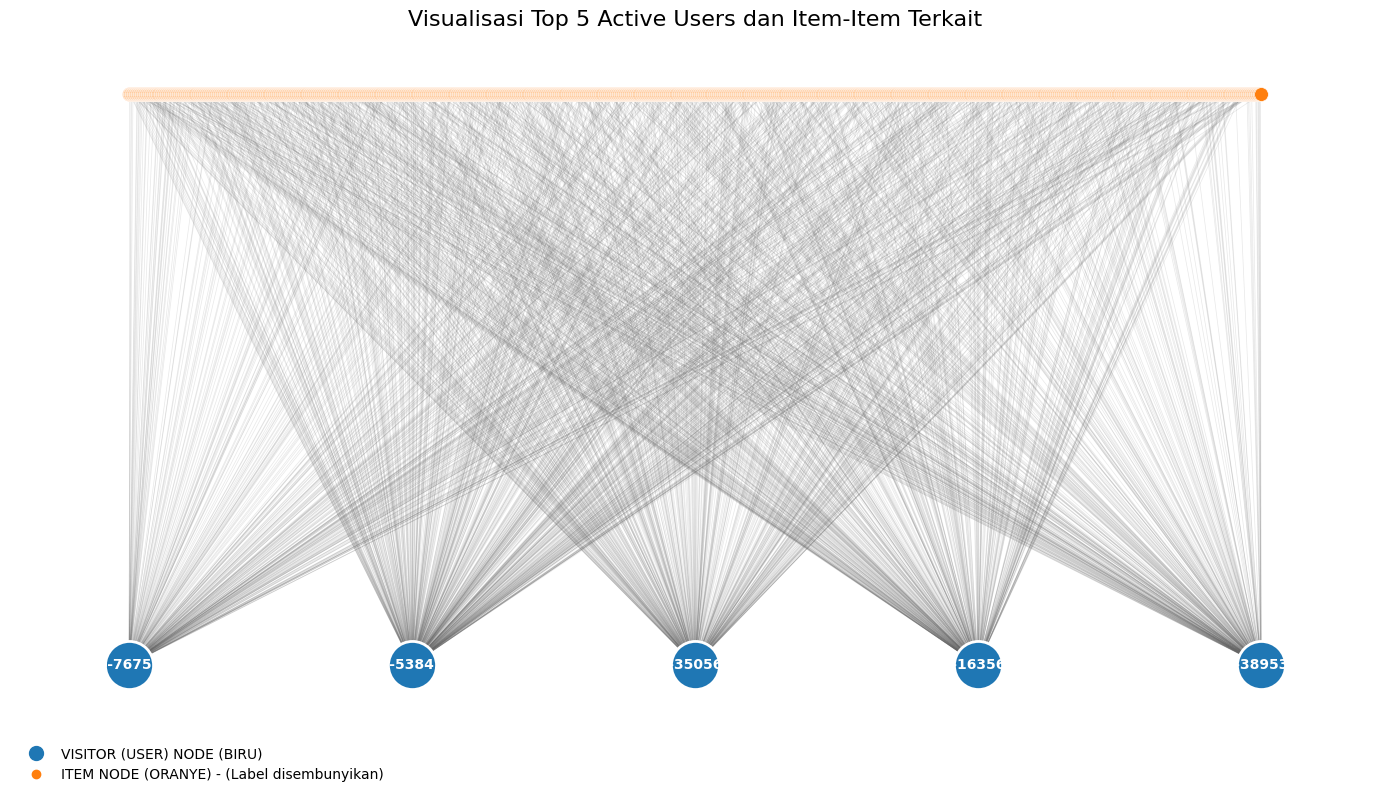

VSM USER (VISITOR)
• Shape Matriks (Dimensi) : (155916, 78171) (Jumlah User x Jumlah Item)
• Jumlah User (Baris)     : 155,916
• Dimensi Vektor (Kolom)  : 78,171


In [18]:
from scipy.sparse import csr_matrix

# konstruksi matriks VSM User & sample Top 5 Active Users
user_ids = df_p1['visitorid'].astype('category')
item_ids = df_p1['itemid'].astype('category')
vsm_user_sparse = csr_matrix((np.ones(len(df_p1)), (user_ids.cat.codes, item_ids.cat.codes)))
top_users = df_p1['visitorid'].value_counts().head(5).index
sample_user_df = df_p1[df_p1['visitorid'].isin(top_users)]

# inisialisasi Graf NetworkX
G_user = nx.Graph()
for _, row in sample_user_df.iterrows():
    G_user.add_node(f"U_{row['visitorid']}", type='User', id=f"U-{row['visitorid']}")
    G_user.add_node(f"I_{row['itemid']}", type='Item')
    G_user.add_edge(f"U_{row['visitorid']}", f"I_{row['itemid']}")

# visualisasi
pos = nx.bipartite_layout(G_user, [n for n, d in G_user.nodes(data=True) if d.get('type') == 'User'], align='horizontal')

# pisahkan node User dan Item untuk pewarnaan dan ukuran kustom
user_nodes = [n for n, d in G_user.nodes(data=True) if d.get('type') == 'User']
item_nodes = [n for n, d in G_user.nodes(data=True) if d.get('type') == 'Item']

user_labels = {n: d.get('id', n) for n, d in G_user.nodes(data=True) if d.get('type') == 'User'}

plt.figure(figsize=(14, 8))
plt.title("Visualisasi Top 5 Active Users dan Item-Item Terkait", fontsize=16)

# background
ax = plt.gca()
ax.set_facecolor('#fdfdfd')

nx.draw_networkx_nodes(G_user, pos, nodelist=user_nodes, node_size=1200, node_color='#1f77b4', edgecolors='white', linewidths=2)
nx.draw_networkx_labels(G_user, pos, labels=user_labels, font_size=10, font_weight='bold', font_color='white')

nx.draw_networkx_nodes(G_user, pos, nodelist=item_nodes, node_size=100, node_color='#ff7f0e', edgecolors='white', linewidths=0.5)

# gambar sisi
nx.draw_networkx_edges(G_user, pos, alpha=0.15, edge_color='#666666', width=0.5)

# legenda kustom
import matplotlib.lines as mlines
user_leg = mlines.Line2D([], [], color='#1f77b4', marker='o', linestyle='None', markersize=10, label='VISITOR (USER) NODE (BIRU)')
item_leg = mlines.Line2D([], [], color='#ff7f0e', marker='o', linestyle='None', markersize=6, label='ITEM NODE (ORANYE) - (Label disembunyikan)')
plt.legend(handles=[user_leg, item_leg], loc='lower left', bbox_to_anchor=(0.0, -0.1), frameon=False)

plt.axis('off') 
plt.tight_layout()
plt.show()

print("VSM USER (VISITOR)")
print(f"• Shape Matriks (Dimensi) : {vsm_user_sparse.shape} (Jumlah User x Jumlah Item)")
print(f"• Jumlah User (Baris)     : {vsm_user_sparse.shape[0]:,}")
print(f"• Dimensi Vektor (Kolom)  : {vsm_user_sparse.shape[1]:,}")

Berdasarkan hasil diatas, karakteristik VSM User dapat diuraikan sebagai berikut:
- Shape Matriks & Dimensi:Shape Matriks: (155916, 78171)   
- Jumlah User / Baris (N): 155.916 simpul Visitor
- Dimensi Vektor / Kolom (M): 78.171 dimensi Item
- Representasi Vektor: Setiap User u_i dinyatakan sebagai vektor V(u_i) = [w_{i,1}, w_{i,2}, \dots, w_{i,78171}]$, di mana $w_{i,j}$ bernilai $1$ jika terjadi interaksi di P1 dan $0$ jika tidak ada.
- Tingkat Kepadatan Matriks (Sparsity): Matriks VSM ini tergolong sangat sparse (jarang terisi). Dengan total sel sebanyak $155.916 \times 78.171 \approx 12,18$ Miliar sel, hanya $296.319$ sel yang terisi angka $> 0$ (berdasarkan total edge P1). Tingkat kerapatan matriks (density) hanya sebesar $\approx 0,0024\%$, artinya perlu menggunakan format matriks terkompresi seperti csr_matrix dari library scipy.sparse untuk efisiensi RAM.

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

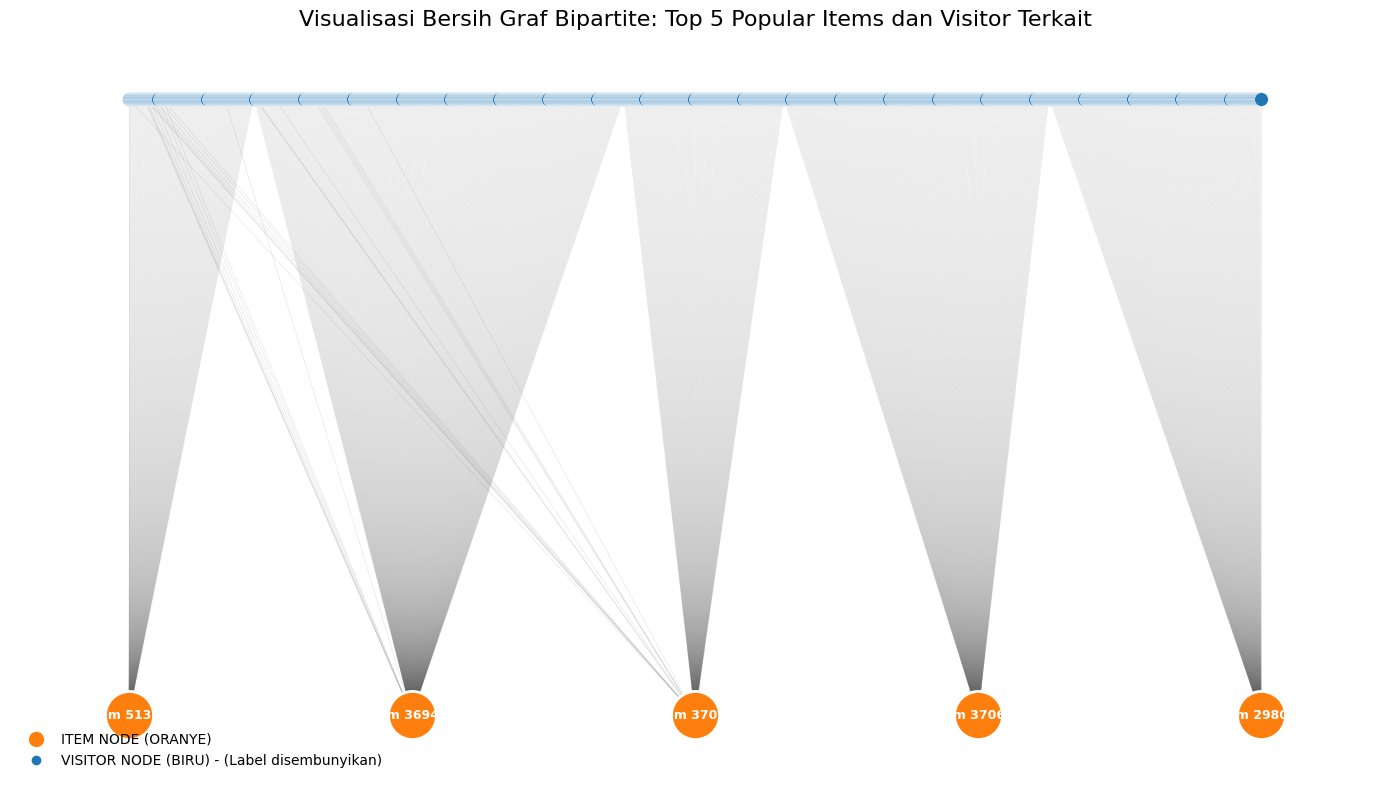

=== VSM ITEM ===
• Shape Matriks (Dimensi) : (78171, 155916) (Jumlah Item x Jumlah User)
• Jumlah Item (Baris)     : 78,171
• Dimensi Vektor (Kolom)  : 155,916
• Total Elemen Terisi     : 231,267 interaksi


In [ ]:
import matplotlib.lines as mlines

vsm_item_sparse = csr_matrix(
    (np.ones(len(df_p1)), (item_ids.cat.codes, user_ids.cat.codes))
)

top_items = df_p1['itemid'].value_counts().head(5).index
sample_item_df = df_p1[df_p1['itemid'].isin(top_items)]

# inisialisasi Graf NetworkX
G_item = nx.Graph()
for _, row in sample_item_df.iterrows():
    G_item.add_node(f"I_{row['itemid']}", type='Item', label=f"Item {row['itemid']}")
    G_item.add_node(f"U_{row['visitorid']}", type='User')
    G_item.add_edge(f"I_{row['itemid']}", f"U_{row['visitorid']}")

pos_i = nx.bipartite_layout(
    G_item, 
    [n for n, d in G_item.nodes(data=True) if d.get('type') == 'Item'], 
    align='horizontal'
)

item_nodes = [n for n, d in G_item.nodes(data=True) if d.get('type') == 'Item']
user_nodes_i = [n for n, d in G_item.nodes(data=True) if d.get('type') == 'User']
item_labels = {n: d.get('label', n) for n, d in G_item.nodes(data=True) if d.get('type') == 'Item'}

# visualisasi
plt.figure(figsize=(14, 8))
plt.title("Visualisasi Bersih Graf Bipartite: Top 5 Popular Items dan Visitor Terkait", fontsize=16)

ax = plt.gca()
ax.set_facecolor('#fdfdfd')

nx.draw_networkx_nodes(G_item, pos_i, nodelist=item_nodes, node_size=1200, node_color='#ff7f0e', edgecolors='white', linewidths=2)
nx.draw_networkx_labels(G_item, pos_i, labels=item_labels, font_size=9, font_weight='bold', font_color='white')

nx.draw_networkx_nodes(G_item, pos_i, nodelist=user_nodes_i, node_size=100, node_color='#1f77b4', edgecolors='white', linewidths=0.5)

nx.draw_networkx_edges(G_item, pos_i, alpha=0.15, edge_color='#666666', width=0.5)

# legenda
item_leg = mlines.Line2D([], [], color='#ff7f0e', marker='o', linestyle='None', markersize=10, label='ITEM NODE (ORANYE)')
user_leg = mlines.Line2D([], [], color='#1f77b4', marker='o', linestyle='None', markersize=6, label='VISITOR NODE (BIRU) - (Label disembunyikan)')
plt.legend(handles=[item_leg, user_leg], loc='lower left', frameon=False)

plt.axis('off')
plt.tight_layout()
plt.show()

print("VSM ITEM")
print(f"• Shape Matriks (Dimensi) : {vsm_item_sparse.shape} (Jumlah Item x Jumlah User)")
print(f"• Jumlah Item (Baris)     : {vsm_item_sparse.shape[0]:,}")
print(f"• Dimensi Vektor (Kolom)  : {vsm_item_sparse.shape[1]:,}")
print(f"• Total Elemen Terisi     : {vsm_item_sparse.nnz:,} interaksi")

Berdasarkan hasil diatas, karakteristik dari VSM Item adalah sebagai berikut:
- Shape Matriks & Dimensi:Shape Matriks: (78171, 155916) (Jumlah Item $\times$ Jumlah User)   
- Jumlah Item / Baris ($M$): 78.171 simpul Item   
- Dimensi Vektor / Kolom ($N$): 155.916 dimensi Visitor (User)   
- Total Elemen Terisi: 231.267 interaksi   
- Representasi Vektor: Setiap produk $i_k$ dinyatakan sebagai vektor $V(i_k) = [w_{k,1}, w_{k,2}, \dots, w_{k,155916}]$, di mana $w_{k,j}$ merepresentasikan adanya akses/transaksi dari visitor $j$.   
- Sparsity & Efisiensi Komputasi:Dengan total kapasitas matriks sebesar $78.171 \times 155.916 \approx 12,18$ Miliar sel, hanya $231.267$ elemen yang bernilai tidak nol ($> 0$). Matriks ini memiliki tingkat sparsity yang sangat tinggi ($\approx 0,0019\%$). Penggunaan struktur data Compressed Sparse Row (csr_matrix) memungkinkan komputasi Cosine Similarity antar-item berjalan secara cepat dan hemat memori.

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!
Berdasarkan eksplorasi VSM User dan VSM Item, proyeksi yang jauh lebih efektif dan efisien untuk diterapkan pada dataset e-commerce ini adalah Proyeksi Item-based Collaborative Filtering (VSM Item). Karena ada beberapa perbandingan yang membuktikan bahwa VSM item lebih efektif daripada VSM User, antara lain:
- pada platform e-commerce, jumlah pengunjung (visitors) tumbuh jauh lebih cepat dan dinamis dibandingkan katalog produk. Menghitung kemiripan berbasis Item ($78.171 \times 78.171$) jauh lebih efisien untuk disimpan di database Neo4j dibanding menghitung kemiripan berbasis User ($155.916 \times 155.916$), yang membutuhkan ruang matriks 4 kali lebih besar.
- Skor similarity antar-item dapat dihitung secara offline/batch (misal sekali sehari), sedangkan profil User berubah setiap detik saat mereka mengeksplorasi barang baru.
- Vektor User sangat sparse dan tidak memiliki cukup riwayat untuk dicari "kembarannya" (User-KNN). Sebaliknya, produk-produk populer dikunjungi oleh ribuan pengguna berbeda, sehingga vektor Item memiliki sinyal interaksi yang jauh lebih kaya dan stabil untuk dihitung Cosine Similarity-nya.
- VSM item menawarkan skalabilitas tinggi, latensi query Neo4j yang lebih cepat, serta mengatasi masalah sparsity pengguna anonim dengan memanfaatkan histori kolektif dari katalog produk

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [8]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

user_ids = df_p1['visitorid'].astype('category')
item_ids = df_p1['itemid'].astype('category')

vsm_item_sparse = csr_matrix(
    (np.ones(len(df_p1)), (item_ids.cat.codes, user_ids.cat.codes))
)

# 100 Item terpopuler di P1
top_100_item_codes = df_p1['itemid'].astype('category').cat.codes.value_counts().head(100).index
vsm_item_sub = vsm_item_sparse[top_100_item_codes]

# Cosine Similarity Matriks
sim_matrix = cosine_similarity(vsm_item_sub)
categories_item = df_p1['itemid'].astype('category').cat.categories

all_sim_items = []
for i_idx, code in enumerate(top_100_item_codes):
    src_item_id = int(categories_item[code])
    top5_idx = np.argsort(sim_matrix[i_idx])[::-1][1:6] # Ambil Top 5 mirip (selain dirinya sendiri)
    
    for neighbor_idx in top5_idx:
        similar_item_id = int(categories_item[top_100_item_codes[neighbor_idx]])
        score = float(sim_matrix[i_idx][neighbor_idx])
        if score > 0: 
            all_sim_items.append({"item1": src_item_id, "item2": similar_item_id, "score": score})

# simpan relasi :SIMILAR ke Neo4j
create_sim_query = """
UNWIND $data AS row
MATCH (i1:Item {itemid: row.item1})
MATCH (i2:Item {itemid: row.item2})
MERGE (i1)-[s:SIMILAR]->(i2)
SET s.score = row.score
RETURN count(s) AS total_relasi_terbuat
"""

with driver.session() as session:
    res_sim = session.run(create_sim_query, data=all_sim_items).single()

print(f"Berhasil membuat {res_sim['total_relasi_terbuat']} relasi :SIMILAR di database Neo4j!")

Berhasil membuat 435 relasi :SIMILAR di database Neo4j!


8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity
- Sebelum perhitungan similarity (studi kasus item 369447)
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemid: 369447})
RETURN v, r, i
LIMIT 20;
Query ini mengekstrak interaksi pengguna terhadap Item target 369447 sebelum algoritma VSM dijalankan. Pada tahap ini, Item 369447 hanya terhubung ke simpul-simpul Visitor (biru) dan tidak memiliki relasi horizontal ke produk lain.
- Setelah perhitungan similarity (studi kasus item 369447)
MATCH (i1:Item {itemid: 369447})-[s:SIMILAR]->(i2:Item)
OPTIONAL MATCH (v:Visitor)-[r]->(i1)
RETURN i1, s, i2, v, r
LIMIT 20;
Query ini menampilkan struktur graf Item 369447 setelah matriks Cosine Similarity disimpan ke Neo4j. Terlihat adanya pembentukan relasi horizontal baru :SIMILAR yang menghubungkan Item 369447 secara langsung ke produk-produk lain (i2) beserta nilai skor kemiripannya (score: 0.08354926311723322)
*Untuk visualisasi graf nya akan dilampirkan dilaporan*

2.2 Analytics

 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
 - (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
 - (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [4]:
import numpy as np
import pandas as pd
import math

p1_start_dt = pd.Timestamp("2015-05-03 00:00:00", tz="UTC")
p1_end_dt   = pd.Timestamp("2015-05-17 23:59:59", tz="UTC")
P1_START    = int(p1_start_dt.timestamp() * 1000)
P1_END      = int(p1_end_dt.timestamp() * 1000)

# daftar user di P1 yang item-itemnya sudah memiliki relasi :SIMILAR di Neo4j
query_eligible_users = """
MATCH (v:Visitor)-[r]->(i1:Item)-[s:SIMILAR]->(i2:Item)
WHERE r.timestamp >= $p1_start AND r.timestamp <= $p1_end
RETURN DISTINCT v.visitorid AS visitorid
"""

with driver.session() as session:
    res_users = session.run(query_eligible_users, p1_start=P1_START, p1_end=P1_END)
    eligible_p1_users = [r['visitorid'] for r in res_users]

p2_users = set(df_p2['visitorid'].unique())
common_eligible_users = sorted(list(set(eligible_p1_users).intersection(p2_users)))

# target user secara acak dan reproducible 
np.random.seed(42)
target_user = int(np.random.choice(common_eligible_users))
print(f"Target User Acak Terpilih (Reproducible): {target_user}")

# query Item-KNN Rekomendasi dari Graf Neo4j
query_knn = """
MATCH (v:Visitor {visitorid: $user_id})-[r]->(i1:Item)-[s:SIMILAR]->(i2:Item)
WHERE r.timestamp >= $p1_start AND r.timestamp <= $p1_end
  AND NOT (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2)
RETURN i2.itemid AS recommended_item, 
       max(s.score) AS similarity_score
ORDER BY similarity_score DESC
LIMIT 5
"""

with driver.session() as session:
    res_knn = session.run(query_knn, user_id=target_user, p1_start=P1_START, p1_end=P1_END)
    df_recs = pd.DataFrame([r.data() for r in res_knn])

print("\nHASIL REKOMENDASI KNN (k=5) BERBASIS GRAF NEO4J:")
print(df_recs)

top_5_recs = df_recs['recommended_item'].tolist()
top_3_recs = top_5_recs[:3]

print(f"\n3 Item yang Diiklankan untuk Target User {target_user}:")
for rank, item_id in enumerate(top_3_recs, 1):
    print(f"   {rank}. Item ID: {item_id}")

Target User Acak Terpilih (Reproducible): 763141

HASIL REKOMENDASI KNN (k=5) BERBASIS GRAF NEO4J:
   recommended_item  similarity_score
0            320130          0.136635
1            215596          0.106887
2            463617          0.088307
3            369447          0.088159
4            387373          0.086872

3 Item yang Diiklankan untuk Target User 763141:
   1. Item ID: 320130
   2. Item ID: 215596
   3. Item ID: 463617


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
- (a) Hit@5
- (b) NDCG@5

In [5]:
ground_truth_p2 = set(df_p2[df_p2['visitorid'] == target_user]['itemid'].unique())
print(f"Ground Truth Item User {target_user} pada Periode P2 (Testing):")
print(f"   {list(ground_truth_p2)}")

# a. hitung Hit@5
hits = [1 if item in ground_truth_p2 else 0 for item in top_5_recs]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

print(f"\nHit@5 Score : {hit_at_5}")

# b. hitung NDCG@5
dcg = 0.0
for rank, is_hit in enumerate(hits, start=1):
    if is_hit:
        dcg += 1.0 / math.log2(rank + 1)

ideal_hits = min(len(ground_truth_p2), 5)
idcg = sum([1.0 / math.log2(r + 1) for r in range(1, ideal_hits + 1)]) if ideal_hits > 0 else 1.0

ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print(f"NDCG@5 Score: {ndcg_at_5:.4f}")

Ground Truth Item User 763141 pada Periode P2 (Testing):
   [np.int64(261793), np.int64(221963), np.int64(29196), np.int64(153035), np.int64(373360), np.int64(268883), np.int64(196629), np.int64(221790), np.int64(185535)]

Hit@5 Score : 0.0
NDCG@5 Score: 0.0000


In [19]:
import numpy as np
import pandas as pd
import math

p1_start_dt = pd.Timestamp("2015-05-03 00:00:00", tz="UTC")
p1_end_dt   = pd.Timestamp("2015-05-17 23:59:59", tz="UTC")
P1_START    = int(p1_start_dt.timestamp() * 1000)
P1_END      = int(p1_end_dt.timestamp() * 1000)

# daftar user di P1 yang item-itemnya sudah memiliki relasi :SIMILAR di Neo4j
query_eligible_users = """
MATCH (v:Visitor)-[r]->(i1:Item)-[s:SIMILAR]->(i2:Item)
WHERE r.timestamp >= $p1_start AND r.timestamp <= $p1_end
RETURN DISTINCT v.visitorid AS visitorid
"""

with driver.session() as session:
    res_users = session.run(query_eligible_users, p1_start=P1_START, p1_end=P1_END)
    eligible_p1_users = [r['visitorid'] for r in res_users]

p2_users = set(df_p2['visitorid'].unique())
common_eligible_users = sorted(list(set(eligible_p1_users).intersection(p2_users)))

# target user secara acak dan reproducible 
np.random.seed(1999)
target_user = int(np.random.choice(common_eligible_users))
print(f"Target User Acak Terpilih (Reproducible): {target_user}")

# query Item-KNN Rekomendasi dari Graf Neo4j
query_knn = """
MATCH (v:Visitor {visitorid: $user_id})-[r]->(i1:Item)-[s:SIMILAR]->(i2:Item)
WHERE r.timestamp >= $p1_start AND r.timestamp <= $p1_end
  AND NOT (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2)
RETURN i2.itemid AS recommended_item, 
       max(s.score) AS similarity_score
ORDER BY similarity_score DESC
LIMIT 5
"""

with driver.session() as session:
    res_knn = session.run(query_knn, user_id=target_user, p1_start=P1_START, p1_end=P1_END)
    df_recs = pd.DataFrame([r.data() for r in res_knn])

print("\nHASIL REKOMENDASI KNN (k=5) BERBASIS GRAF NEO4J:")
print(df_recs)

top_5_recs = df_recs['recommended_item'].tolist()
top_3_recs = top_5_recs[:3]

print(f"\n3 Item yang Diiklankan untuk Target User {target_user}:")
for rank, item_id in enumerate(top_3_recs, 1):
    print(f"   {rank}. Item ID: {item_id}")

Target User Acak Terpilih (Reproducible): 79627

HASIL REKOMENDASI KNN (k=5) BERBASIS GRAF NEO4J:
   recommended_item  similarity_score
0            316753          0.192765
1             69533          0.177262
2            320130          0.136635
3             84160          0.123473
4             48743          0.117846

3 Item yang Diiklankan untuk Target User 79627:
   1. Item ID: 316753
   2. Item ID: 69533
   3. Item ID: 320130


In [20]:
ground_truth_p2 = set(df_p2[df_p2['visitorid'] == target_user]['itemid'].unique())
print(f"Ground Truth Item User {target_user} pada Periode P2 (Testing):")
print(f"   {list(ground_truth_p2)}")

# a. hitung Hit@5
hits = [1 if item in ground_truth_p2 else 0 for item in top_5_recs]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

print(f"\nHit@5 Score : {hit_at_5}")

# b. hitung NDCG@5
dcg = 0.0
for rank, is_hit in enumerate(hits, start=1):
    if is_hit:
        dcg += 1.0 / math.log2(rank + 1)

ideal_hits = min(len(ground_truth_p2), 5)
idcg = sum([1.0 / math.log2(r + 1) for r in range(1, ideal_hits + 1)]) if ideal_hits > 0 else 1.0

ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print(f"NDCG@5 Score: {ndcg_at_5:.4f}")

Ground Truth Item User 79627 pada Periode P2 (Testing):
   [np.int64(228611), np.int64(32015), np.int64(417682), np.int64(464278), np.int64(238233), np.int64(117274), np.int64(135837), np.int64(159780), np.int64(89775), np.int64(399484), np.int64(157743), np.int64(203957), np.int64(190654), np.int64(66752), np.int64(50499), np.int64(329028), np.int64(318789), np.int64(114250), np.int64(223820), np.int64(173014), np.int64(166358), np.int64(162139), np.int64(147422), np.int64(115166), np.int64(50284), np.int64(452720), np.int64(139770), np.int64(440188)]

Hit@5 Score : 0.0
NDCG@5 Score: 0.0000
